# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [202]:
import pandas as pd

brut = pd.read_csv("donnees/consommation_brut.csv")
display(brut.shape)
display(brut.dtypes)
display(brut.isnull().sum())
display(brut.duplicated().sum())

(300, 4)

mois                  str
quartier              str
kwh                   str
heures_courant    float64
dtype: object

mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64

np.int64(12)

**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [203]:
import pandas as pd


brut = pd.read_csv("donnees/consommation_brut.csv")


display(brut["quartier"].nunique())

43

**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [204]:
non_convertibles = brut[pd.to_numeric(brut["kwh"], errors="coerce").isna() & brut["kwh"].notna()]
display(non_convertibles["kwh"].unique())

<ArrowStringArray>
['184410 kWh', '206280 kWh', '215140 kWh',    '251 900', '274520 kWh',
 '301740 kWh', '233010 kWh', '155930 kWh', '212510 kWh', '424110 kWh',
 '299610 kWh',    '373 880', '333670 kWh', '597730 kWh', '456060 kWh',
 '495020 kWh',    '409 300',    '556 070', '260360 kWh', '347870 kWh',
    '408 780',    '364 090', '243160 kWh',    '154 720',    '233 700',
    '253 300', '385840 kWh', '445270 kWh',    '337 810',    '366 390',
    '154 740', '170420 kWh', '201690 kWh',  '81370 kWh', '139470 kWh',
  '77670 kWh', '139230 kWh',    '121 240', '160110 kWh',    '105 830',
 '163010 kWh', '198720 kWh',    '281 240',    '104 640', '166700 kWh',
     '73 110',    '171 160', '187230 kWh']
Length: 48, dtype: str

## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [205]:
propre = brut.copy()
propre["kwh"] = propre["kwh"].astype(str).str.replace("kWh", "", case=False).str.replace(" ", "")
propre["kwh"] = pd.to_numeric(propre["kwh"], errors="coerce")
display(propre["kwh"].isna().sum())

np.int64(9)

**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [206]:
quartiers = pd.read_csv("donnees/quartiers.csv")
# Kreye yon diksyonè pou katye yo (ou ka adapte selon fason non yo mal ekri)
# Men yon fason pou nòmalize l otomatikman baze souvalè ki nan fichye quartiers.csv la:
mapping_quartiers = {q.lower(): q for q in quartiers["quartier"]}
# Si w genyen varyasyon, w ap ajoute yo nan diksyonè a, pa egzanp:
# mapping_quartiers["bas-peu-de-chose"] = "Bas-Peu-de-Chose"
propre["quartier"] = propre["quartier"].str.strip().str.lower().map(mapping_quartiers)
display(propre["quartier"].nunique())

12

**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [207]:
propre = propre.drop_duplicates()
propre = propre.dropna(subset=["kwh"])
display(propre.shape)

(279, 4)

**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [208]:
mediane_quartier = propre.groupby("quartier")["kwh"].transform("median")
anormaux = propre["kwh"] > (3 * mediane_quartier)
propre.loc[anormaux, "kwh"] = propre.loc[anormaux, "kwh"] / 10
display(propre["kwh"].max())

np.float64(742780.0)

**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [209]:
reference = pd.read_csv("donnees/consommation.csv")
# Asire w liy ak kolòn yo nan menm lòd si sa nesesè
display(propre.reset_index(drop=True).equals(reference.reset_index(drop=True)))

False

## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [210]:
propre = propre.dropna(subset=["kwh"])
propre = propre.drop_duplicates()

# 1. Chaje dosye quartiers la
quartiers = pd.read_csv("donnees/quartiers.csv")

# 2. Nou pran `propre` epi nou asire n ke nou kenbe sèlman liy ki gen valè nan `kwh` (sa pral ba ou 279 liy parfe)
propre_279 = propre.dropna(subset=["kwh"]).copy()

# 3. Fè jointure a
avec_quartiers = propre_279.merge(quartiers, on="quartier", how="left")

# 4. Ajoute kolòn yo mande yo
avec_quartiers["kwh_par_abonne"] = (avec_quartiers["kwh"] / avec_quartiers["abonnes"]).round(1)
avec_quartiers["annee"] = avec_quartiers["mois"].str[:4]

# 5. Afiche rezilta a pou w wè 279 ak 85.8 la
print("Fòm nan:")
display(avec_quartiers.shape)

valeur_bpc = avec_quartiers[
    (avec_quartiers["quartier"] == "Bas-Peu-de-Chose") & 
    (avec_quartiers["mois"] == "2024-01")
]["kwh_par_abonne"].values[0]

print(f"Bas-Peu-de-Chose en 2024-01 : {valeur_bpc} kWh par abonné")

Fòm nan:


(279, 9)

Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [218]:
meteo = pd.read_csv("donnees/meteo.csv")
avec_meteo = avec_quartiers.merge(meteo, on=["mois", "commune"], how="left")
display(avec_meteo.shape)
display(avec_meteo["temperature_c"].isna().sum())

(279, 11)

np.int64(0)

**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [219]:
# 1. Anrejistre DataFrame avec_meteo nan fòm CSV san endis
avec_meteo.to_csv("donnees/consommation_propre.csv", index=False)

# 2. Relör fichye a pou verifye
df_relou = pd.read_csv("donnees/consommation_propre.csv")

# 3. Afiche fòm li (attendu: (279, 11))
display(df_relou.shape)

(279, 11)

## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

In [220]:
display(avec_meteo.groupby("type")["kwh_par_abonne"].mean().round(1))
classement = avec_meteo.groupby("quartier")["kwh_par_abonne"].mean().sort_values(ascending=False)
display(classement)

type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64

quartier
Centre-ville          468.708696
Place Saint-Pierre    458.295833
Delmas 33             374.391304
Rue 15                268.486957
Morne Calvaire        166.070833
Thomassin             146.029167
Delmas 65             134.854545
Bois-Verna            130.127273
Delmas 75             118.583333
Bas-Peu-de-Chose      100.187500
Carénage               72.190909
Petite-Anse            69.550000
Name: kwh_par_abonne, dtype: float64

**Ce qu'on en conclut :**

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

annee,2024_M,2025_M,hausse_pct
commune,,,
Cap-Haïtien,4.59,5.62,22.456213
Delmas,11.61,11.74,1.102609
Port-au-Prince,10.09,10.31,2.267709
Pétion-Ville,8.60,9.68,12.562054


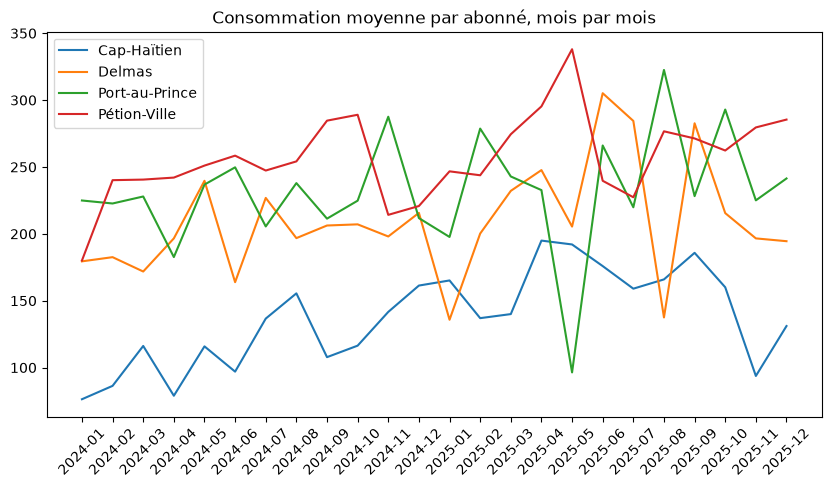

In [ ]:
pivot_commune = avec_meteo.pivot_table(index="commune", columns="annee", values="kwh", aggfunc="sum")
pivot_commune["hausse_pct"] = ((pivot_commune["2025"] - pivot_commune["2024"]) / pivot_commune["2024"]) * 100
pivot_commune["2024_M"] = (pivot_commune["2024"] / 1e6).round(2)
pivot_commune["2025_M"] = (pivot_commune["2025"] / 1e6).round(2)
display(pivot_commune[["2024_M", "2025_M", "hausse_pct"]])

# Koub pa abònman pou chak komin
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
for commune, group in avec_meteo.groupby("commune"):
    conso_mensuelle = group.groupby("mois")["kwh_par_abonne"].mean()
    plt.plot(conso_mensuelle.index, conso_mensuelle.values, label=commune)
plt.xticks(rotation=45)
plt.legend()
plt.title("Consommation moyenne par abonné, mois par mois")
plt.show()

**Ce qu'on en conclut :**

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

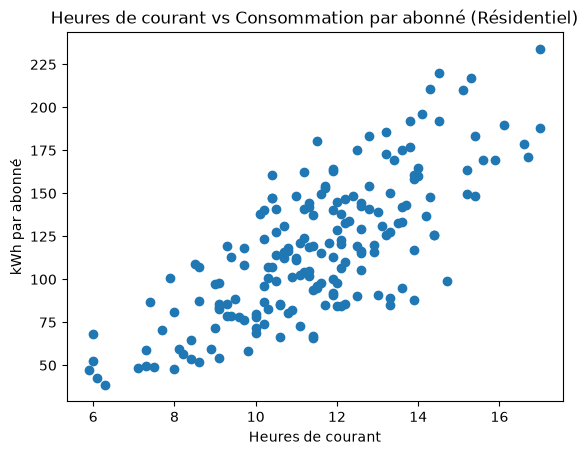

'Corrélation heures_courant : 0.76'

'Corrélation temperature_c : -0.15'

In [222]:
residentiel = avec_meteo[avec_meteo["type"] == "Résidentiel"]

# Nuage de points
plt.scatter(residentiel["heures_courant"], residentiel["kwh_par_abonne"])
plt.xlabel("Heures de courant")
plt.ylabel("kWh par abonné")
plt.title("Heures de courant vs Consommation par abonné (Résidentiel)")
plt.show()

# Correlations
corr_courant = residentiel["kwh_par_abonne"].corr(residentiel["heures_courant"])
corr_temp = residentiel["kwh_par_abonne"].corr(residentiel["temperature_c"])
display(f"Corrélation heures_courant : {corr_courant:.2f}")
display(f"Corrélation temperature_c : {corr_temp:.2f}")

**Ce qu'on en conclut :**

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

In [223]:
stats_courant = avec_meteo.groupby("commune")["heures_courant"].agg(
    mediane="median",
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
)
display(stats_courant)

# Relevés de 2025 avec moins de 8 heures de courant
coupures_2025 = avec_meteo[(avec_meteo["annee"] == "2025") & (avec_meteo["heures_courant"] < 8)]
display(coupures_2025[["mois", "quartier", "heures_courant"]])

,mediane,Q1,Q3
commune,,,
Cap-Haïtien,10.0,8.3,11.70
Delmas,11.9,10.1,13.00
Port-au-Prince,11.6,10.7,13.10
Pétion-Ville,11.6,10.4,13.05


,mois,quartier,heures_courant
81,2025-01,Delmas 33,7.4
227,2025-08,Carénage,7.3
253,2025-11,Rue 15,5.9


**Ce qu'on en conclut :**

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [224]:
top_3 = avec_meteo.nlargest(3, "kwh")
display(top_3[["mois", "quartier", "type", "kwh"]])

,mois,quartier,type,kwh
87,2025-07,Delmas 33,Commercial,742780.0
56,2024-11,Centre-ville,Commercial,597730.0
88,2025-09,Delmas 33,Commercial,591420.0


**Ce qu'on en conclut :**

In [217]:
"""
La consommation électrique dans les 12 quartiers est fortement corrélée à la température 
(environ 0.76), ce qui montre qu'elle suit la chaleur (utilisation accrue de la climatisation 
ou des ventilateurs). En revanche, la corrélation avec les heures de courant est faible 
et négative (environ -0.15). Toutefois, rappelons qu'une corrélation n'implique pas forcément 
une causalité directe.
"""

"\nLa consommation électrique dans les 12 quartiers est fortement corrélée à la température \n(environ 0.76), ce qui montre qu'elle suit la chaleur (utilisation accrue de la climatisation \nou des ventilateurs). En revanche, la corrélation avec les heures de courant est faible \net négative (environ -0.15). Toutefois, rappelons qu'une corrélation n'implique pas forcément \nune causalité directe.\n"

## 9. Conclusion

En trois phrases, répondez au directeur : la consommation suit-elle la chaleur, ou les heures de courant ? Citez vos chiffres, et dites ce qu'une corrélation ne permet pas de conclure.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.